In [ ]:
# Install required libraries
!pip install albumentations opencv-python matplotlib torch torchvision numpy pillow scikit-learn tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Weather Augmentation Module
import albumentations as A

def get_weather_transform():
    transform = A.Compose([
        A.RandomRain(p=0.3),
        A.RandomFog(p=0.3),
        A.RandomSnow(p=0.2),
        A.MotionBlur(p=0.3),
        A.RandomBrightnessContrast(p=0.4),
        A.GaussNoise(p=0.2)
    ])
    return transform

In [ ]:
# Image Enhancement Module
import cv2
import numpy as np

def clahe_enhancement(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)

    merged = cv2.merge((cl, a, b))
    enhanced = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

    return enhanced

def sharpen_image(image):
    kernel = np.array([[0,-1,0],
                       [-1,5,-1],
                       [0,-1,0]])
    return cv2.filter2D(image, -1, kernel)

In [ ]:
# Custom Dataset Loader (DFR Dataset) - Modified for VGG16
import os
import cv2
import torch
from torch.utils.data import Dataset
from torchvision import transforms

class DFRDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.classes = os.listdir(root_dir)
        self.image_paths = []
        self.labels = []

        for label in self.classes:
            class_path = os.path.join(root_dir, label)
            for img in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img))
                self.labels.append(int(label))

        self.weather = get_weather_transform()

        # VGG16 specific normalization (mean and std for ImageNet)
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((224, 224)),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        if img is None:
            print(f"Warning: Could not read image {self.image_paths[idx]}")
            # Return a placeholder or skip
            return self.__getitem__((idx + 1) % len(self.image_paths))

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Weather simulation
        img = self.weather(image=img)['image']

        # Enhancement
        img = clahe_enhancement(img)
        img = sharpen_image(img)

        img = self.transform(img)

        label = torch.tensor(self.labels[idx])

        return img, label

In [ ]:
# VGG16 Model for Traffic Sign Detection
import torch
import torch.nn as nn
import torchvision.models as models

class VGG16_TSD(nn.Module):
    def __init__(self, num_classes):
        super(VGG16_TSD, self).__init__()

        # Load pretrained VGG16
        self.backbone = models.vgg16(pretrained=True)

        # Freeze early layers (optional - helps with overfitting on small datasets)
        # Uncomment to freeze first few layers
        # for param in self.backbone.features[:10].parameters():
        #     param.requires_grad = False

        # Get the number of features from VGG16 classifier
        in_features = self.backbone.classifier[6].in_features  # 4096

        # Replace the classifier with a custom head
        self.backbone.classifier[6] = nn.Identity()

        # Custom Classifier Head
        self.classifier = nn.Sequential(
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        # Extract features using VGG16 backbone
        x = self.backbone(x)

        # Classify using custom head
        x = self.classifier(x)

        return x

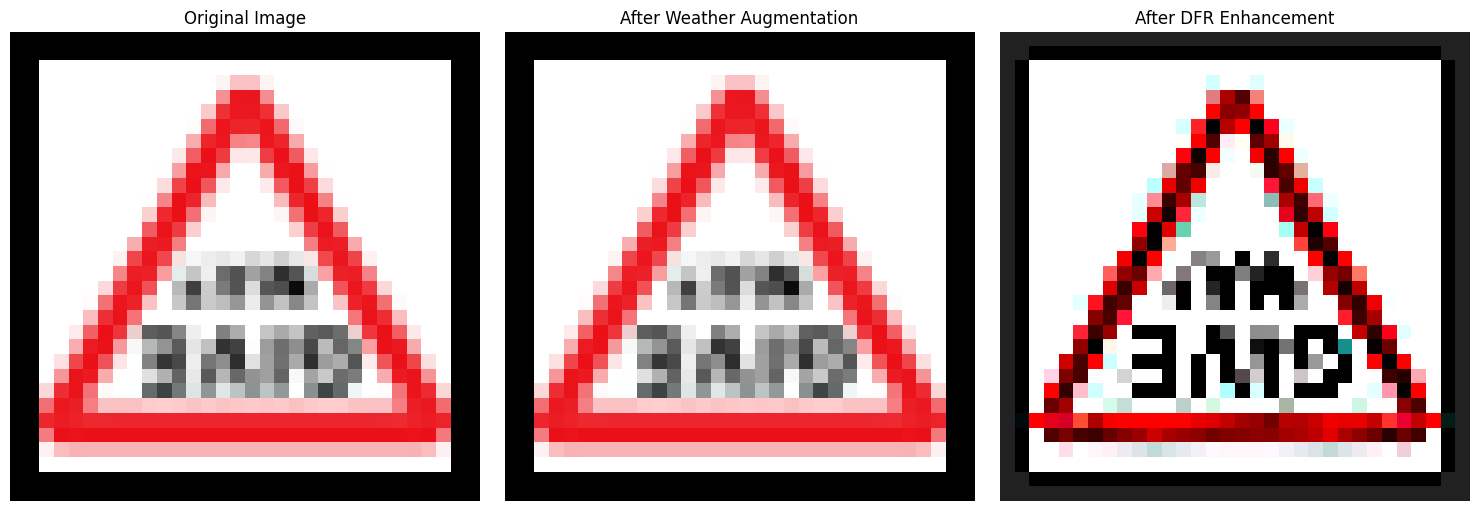

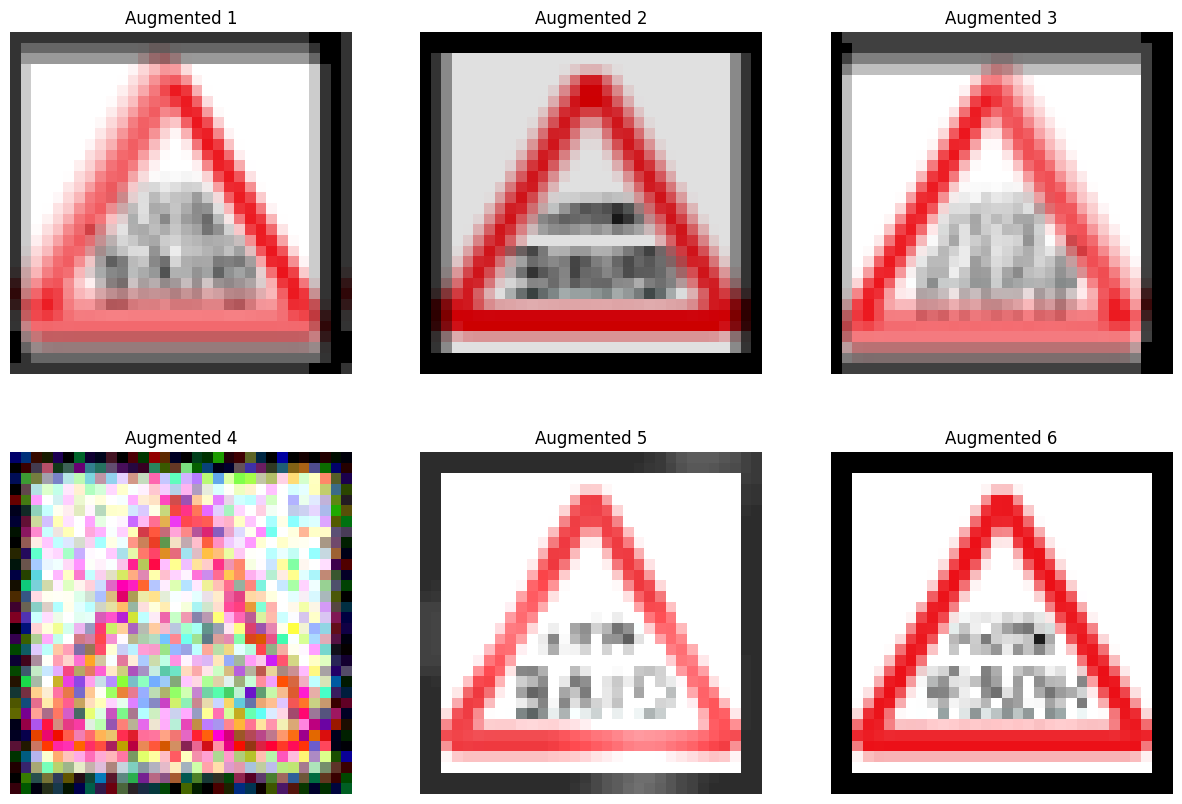

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load one sample image
image_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/0/0_original_43.png_592b345c-34ee-4cc5-b2f4-774db9375ab8.png"  # change to your image path
image = cv2.imread(image_path)
if image is not None:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply Weather Augmentation
    weather = get_weather_transform()
    augmented = weather(image=image)['image']

    # Apply Enhancement Block (DFR Module)
    enhanced = clahe_enhancement(augmented)
    enhanced = sharpen_image(enhanced)

    # Plot Results
    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(augmented)
    plt.title("After Weather Augmentation")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(enhanced)
    plt.title("After DFR Enhancement")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Show multiple augmentations
    plt.figure(figsize=(15,10))
    for i in range(6):
        augmented = weather(image=image)['image']
        plt.subplot(2,3,i+1)
        plt.imshow(augmented)
        plt.title(f"Augmented {i+1}")
        plt.axis("off")
    plt.show()
else:
    print(f"Could not load image from path: {image_path}")

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
import time

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Load Dataset
dataset_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images"
if not os.path.exists(dataset_path):
    print(f"Error: Dataset path {dataset_path} does not exist!")
    # You can set an alternative path here
    # dataset_path = "/path/to/your/dataset"

dataset = DFRDataset(dataset_path)
print(f"Total images in dataset: {len(dataset)}")

# Split into Train & Validation (80-20)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

num_classes = 59  # Number of traffic sign classes

# Initialize VGG16 model
model = VGG16_TSD(num_classes).to(DEVICE)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0001)  # Lower learning rate for VGG16
# Optional: Add learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

EPOCHS = 10

# Store history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
best_val_acc = 0

print("Starting training...")
start_time = time.time()

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss = 0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]')
    for images, labels in train_bar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        # Calculate accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Update progress bar
        train_bar.set_postfix({'loss': loss.item(), 'acc': 100 * correct/total})

    train_accuracy = 100 * correct / total

    # Validation phase
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]')
        for images, labels in val_bar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            val_bar.set_postfix({'loss': loss.item(), 'acc': 100 * correct/total})

    val_accuracy = 100 * correct / total

    # Update learning rate
    scheduler.step()

    # Store metrics
    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss / len(val_loader))
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_acc:
        best_val_acc = val_accuracy
        best_model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/VGG16_TSD_best.pth"
        os.makedirs(os.path.dirname(best_model_path), exist_ok=True)
        torch.save(model.state_dict(), best_model_path)
        print(f" Saved best model with validation accuracy: {val_accuracy:.2f}%")

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accuracy:.2f}%")
    print(f"Current LR: {scheduler.get_last_lr()[0]:.6f}")
    print("-" * 50)

# Save final model
final_model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/VGG16_TSD_final.pth"
torch.save(model.state_dict(), final_model_path)

end_time = time.time()
training_time = end_time - start_time
print(f"\n Training completed in {training_time//60:.0f}m {training_time%60:.0f}s")
print(f"Best validation accuracy: {best_val_acc:.2f}%")

Using device: cuda
Total images in dataset: 13971


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 151MB/s]


Starting training...


Epoch 1/10 [Val]: 100%|██████████| 88/88 [09:26<00:00,  6.44s/it, loss=2.02, acc=25.8]


... (15 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 88/88 [00:29<00:00,  2.97it/s, loss=0.365, acc=79.6]


 Saved best model with validation accuracy: 79.61%

Epoch [9/10]
Train Loss: 0.6394, Train Acc: 78.75%
Val Loss: 0.5898, Val Acc: 79.61%
Current LR: 0.000010
--------------------------------------------------


Epoch 10/10 [Val]: 100%|██████████| 88/88 [00:28<00:00,  3.06it/s, loss=0.467, acc=80.1]


 Saved best model with validation accuracy: 80.07%

Epoch [10/10]
Train Loss: 0.6157, Train Acc: 79.66%
Val Loss: 0.5801, Val Acc: 80.07%
Current LR: 0.000001
--------------------------------------------------

 Training completed in 79m 59s
Best validation accuracy: 80.07%


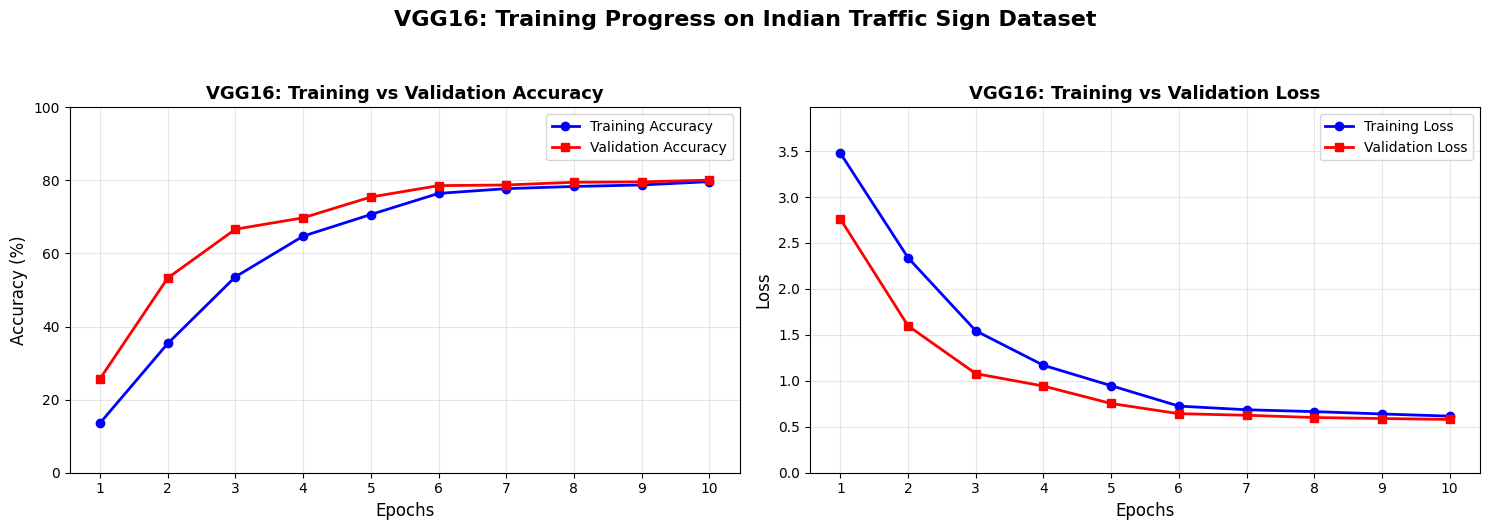

Final Training Accuracy: 79.66%
Final Validation Accuracy: 80.07%
Best Validation Accuracy: 80.07%
Final Training Loss: 0.6157
Final Validation Loss: 0.5801


In [ ]:
import matplotlib.pyplot as plt

# Your data from training
epochs = list(range(1, EPOCHS + 1))

# Create figure with 2 subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Accuracy
ax1.plot(epochs, train_accuracies, 'b-', marker='o', linewidth=2, markersize=6, label='Training Accuracy')
ax1.plot(epochs, val_accuracies, 'r-', marker='s', linewidth=2, markersize=6, label='Validation Accuracy')
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.set_title('VGG16: Training vs Validation Accuracy', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(epochs)
ax1.set_ylim(0, 100)

# Plot 2: Loss
ax2.plot(epochs, train_losses, 'b-', marker='o', linewidth=2, markersize=6, label='Training Loss')
ax2.plot(epochs, val_losses, 'r-', marker='s', linewidth=2, markersize=6, label='Validation Loss')
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('VGG16: Training vs Validation Loss', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xticks(epochs)
ax2.set_ylim(0, max(max(train_losses), max(val_losses)) + 0.5)

# Add a main title
fig.suptitle('VGG16: Training Progress on Indian Traffic Sign Dataset', fontsize=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

# Print final results
print(f"Final Training Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"Best Validation Accuracy: {max(val_accuracies):.2f}%")
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Loss: {val_losses[-1]:.4f}")

Class names loaded successfully


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded successfully!

 Predicted Class: 1
 Sign Name: No entry
 Confidence: 94.92%

 Top 5 Predictions:
   1. Class 1: No entry (94.92%)
   2. Class 7: No entry for pedestrians (2.80%)
   3. Class 15: No left turn (0.75%)
   4. Class 28: Narrow bridge (0.40%)
   5. Class 17: No overtaking (0.24%)


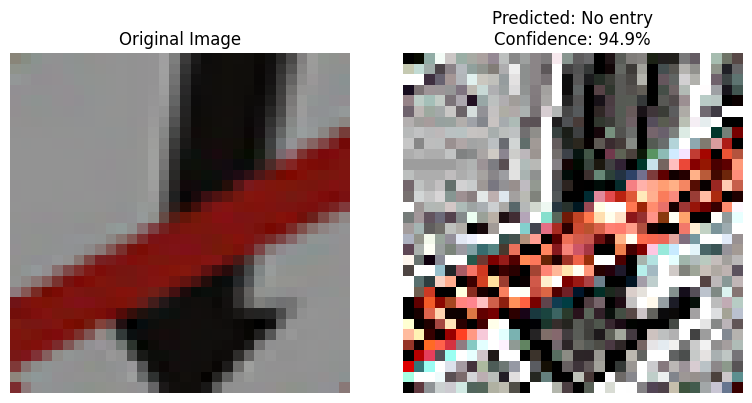

In [ ]:
import torch
import cv2
import numpy as np

# Load class names from CSV
import pandas as pd
csv_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/traffic_sign.csv"  # Update path if needed

try:
    df = pd.read_csv(csv_path)
    class_names = dict(zip(df['ClassId'], df['Name']))
    print("Class names loaded successfully")
except:
    # Fallback if CSV not found
    class_names = {i: f"Class {i}" for i in range(59)}
    print("Using default class names")

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the trained VGG16 model
model = VGG16_TSD(num_classes=59)
model.load_state_dict(torch.load("/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/VGG16_TSD_best.pth",
                                 map_location=DEVICE))
model = model.to(DEVICE)
model.eval()

print("Model loaded successfully!")

# Define the same transform used during training
from torchvision import transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                       std=[0.229, 0.224, 0.225])
])

# Load and preprocess test image
test_image_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/1/1_original_44_original_44.png_0b4c066e-39c0-4b14-a446-85eff9147bda.png_3951454a-434e-4a1c-b27d-9223f1a9d636.png"

image = cv2.imread(test_image_path)
if image is not None:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply DFR Enhancement (optional)
    enhanced = clahe_enhancement(image_rgb)
    enhanced = sharpen_image(enhanced)

    # Transform for model
    image_tensor = transform(enhanced).unsqueeze(0).to(DEVICE)

    # Inference
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)
        confidence, prediction = torch.max(probabilities, dim=1)

    pred_class = prediction.item()
    confidence_score = confidence.item() * 100

    print(f"\n Predicted Class: {pred_class}")
    print(f" Sign Name: {class_names.get(pred_class, 'Unknown')}")
    print(f" Confidence: {confidence_score:.2f}%")

    # Show top 5 predictions
    top5_prob, top5_classes = torch.topk(probabilities, 5)
    print("\n Top 5 Predictions:")
    for i in range(5):
        class_id = top5_classes[0][i].item()
        prob = top5_prob[0][i].item() * 100
        print(f"   {i+1}. Class {class_id}: {class_names.get(class_id, 'Unknown')} ({prob:.2f}%)")

    # Display image
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced)
    plt.title(f"Predicted: {class_names.get(pred_class, 'Unknown')}\nConfidence: {confidence_score:.1f}%")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"Could not load image from path: {test_image_path}")